# V1DD soma coordinates

Read soma `SpatialLocation` rows from the CAVE and streamline-transformed reference spaces written by `etl_v1dd_01_cave_dataset_celltypes.ipynb`, then plot xy and xz projections for both frames.

In [1]:
from pathlib import Path

from matplotlib import pyplot as plt

from connects_common_connectivity.config import get_settings
from connects_common_connectivity.io import read_spatial_locations
from connects_common_connectivity.models import LocationType

## Locate the spatial-location table

Use the configured ETL output when available, otherwise try a mounted Common Connectivity dataset.

In [2]:
PROJECT_ID = "v1dd_1196"
CAVE_REFERENCE_SPACE_ID = "v1dd_cave_nm"
STREAMLINE_REFERENCE_SPACE_ID = "v1dd_streamline_nm"

candidate_roots = [
    Path(get_settings().output_root),
    Path("/data/v1dd_1196_ccm"),
]
output_root = next(
    (candidate for candidate in candidate_roots if (candidate / "spatiallocation").exists()),
    None,
)
if output_root is None:
    raise FileNotFoundError(
        "Could not find a spatiallocation table. Run "
        "etl_v1dd_01_cave_dataset_celltypes.ipynb first or mount its output."
    )

print(f"Reading spatial locations from: {output_root}")

Reading spatial locations from: /scratch/v1dd_ccm_20261012


In [3]:
cave_locations = read_spatial_locations(
    PROJECT_ID,
    reference_spaces=CAVE_REFERENCE_SPACE_ID,
    location_types=LocationType.SOMA,
    output_root=output_root,
).rename({"x": "cave_x", "y": "cave_y", "z": "cave_z"})

streamline_locations = read_spatial_locations(
    PROJECT_ID,
    reference_spaces=STREAMLINE_REFERENCE_SPACE_ID,
    location_types=LocationType.SOMA,
    output_root=output_root,
).rename(
    {"x": "streamline_x", "y": "streamline_y", "z": "streamline_z"}
)

print(
    f"CAVE soma rows: {cave_locations.height}; "
    f"streamline soma rows: {streamline_locations.height}"
)
if cave_locations.is_empty() or streamline_locations.is_empty():
    raise ValueError(
        f"No soma locations found for project {PROJECT_ID!r} in one or both "
        "reference spaces. Check the project ID and ETL output root."
    )

soma_spatial = cave_locations.select(
    "dataitem_id", "cave_x", "cave_y", "cave_z"
).join(
    streamline_locations.select(
        "dataitem_id", "streamline_x", "streamline_y", "streamline_z"
    ),
    on="dataitem_id",
    how="inner",
)
if soma_spatial.is_empty():
    raise ValueError("CAVE and streamline locations have no matching dataitem_id values.")

print(f"soma rows in both reference spaces: {soma_spatial.height}")
soma_spatial.head()

CAVE soma rows: 143448; streamline soma rows: 143448
soma rows in both reference spaces: 143448


dataitem_id,cave_x,cave_y,cave_z,streamline_x,streamline_y,streamline_z
str,f64,f64,f64,f64,f64,f64
"""864691132654552792""",624680.0,531094.0,283770.0,-248.956909,222.054907,16.022035
"""864691132773514104""",894573.0,478559.0,163530.0,30.864259,135.367984,-105.097754
"""864691132774106773""",1.729859e6,674111.0,781200.0,804.489146,493.264462,468.374144
"""864691132780109973""",1.640231e6,677370.0,768015.0,714.854245,493.32372,454.7348
"""864691132736203675""",1.316562e6,974035.0,157590.0,348.218706,624.53627,-228.775916


## Scatterplots

The xy projections invert the displayed y-axis, matching each reference space's default view of `+X` left-to-right and `-Y` bottom-to-top. The streamline frame also declares pia-to-white-matter along `+Y`.

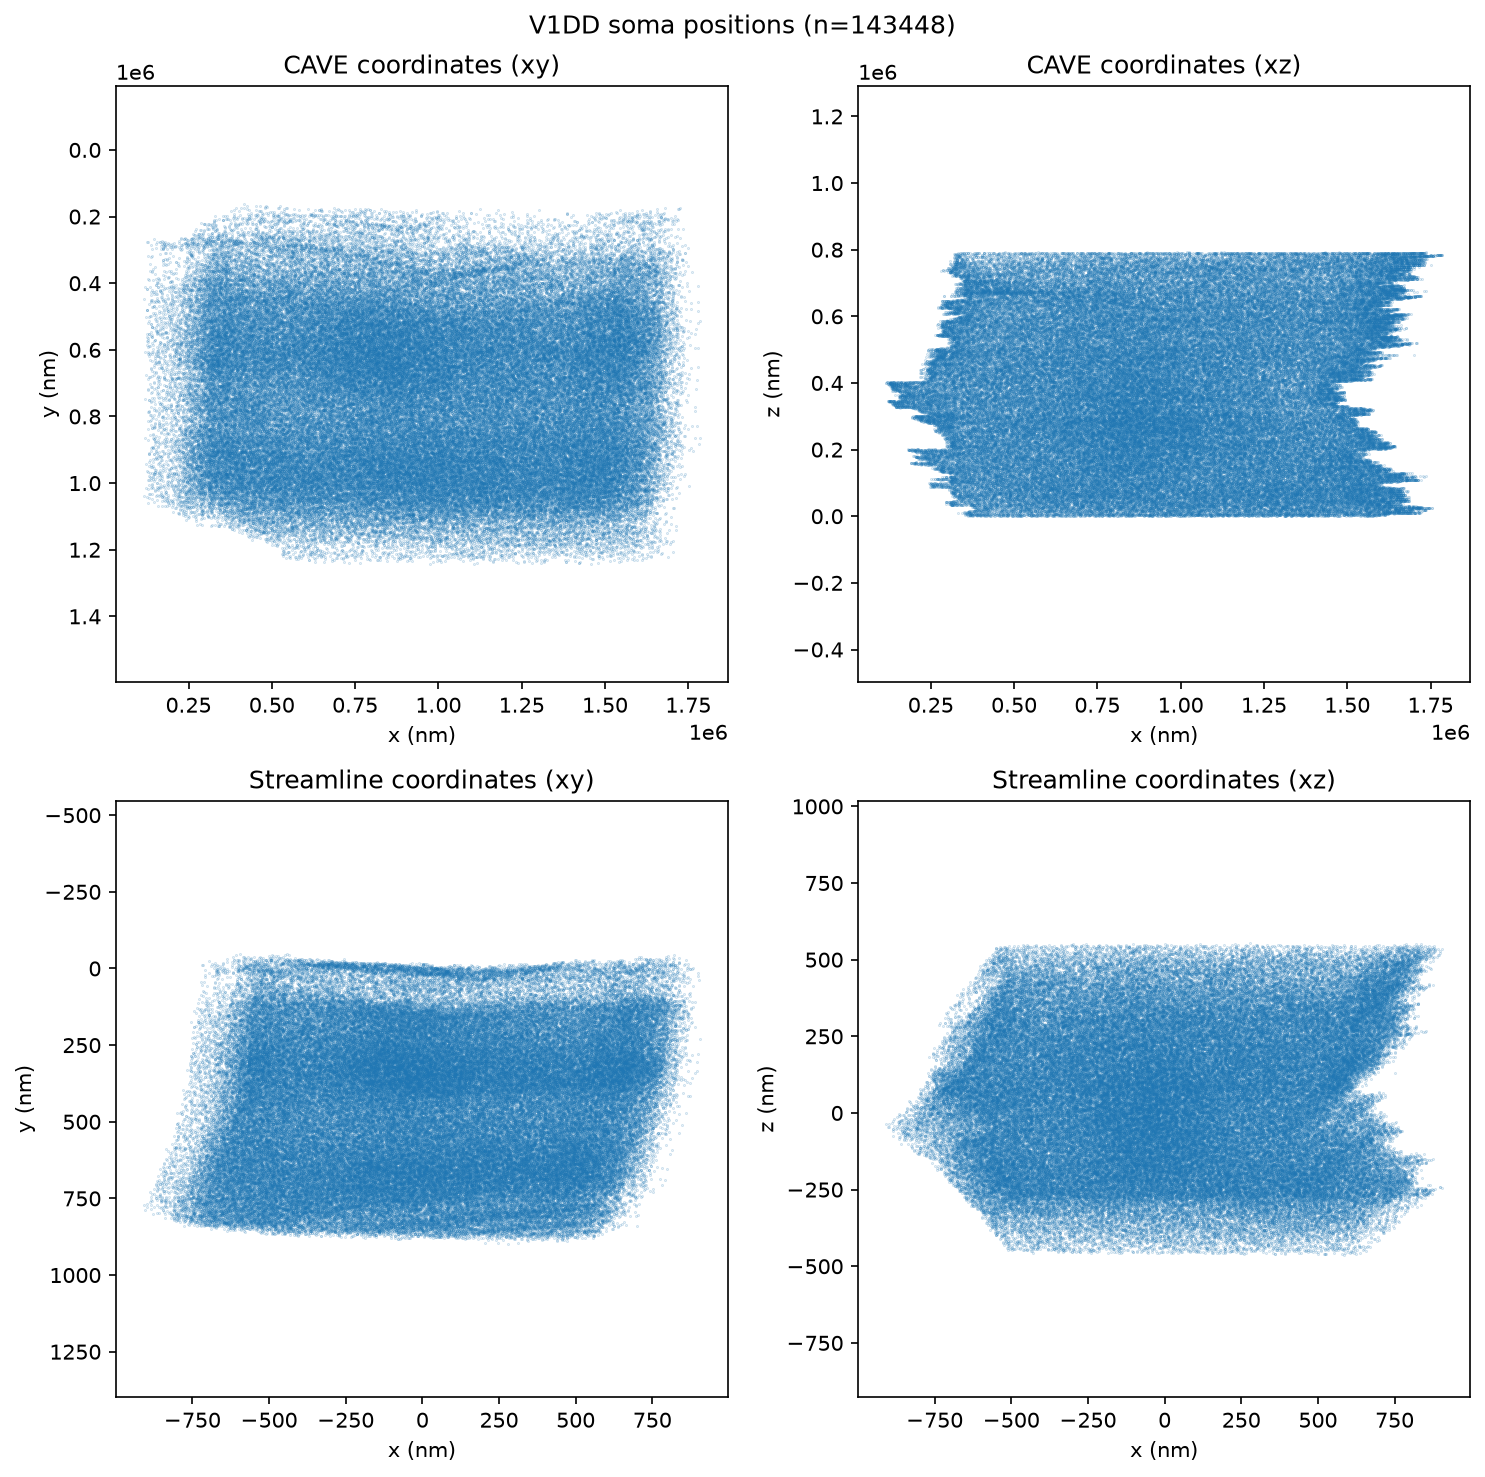

In [4]:
panels = [
    ("cave_x", "cave_y", "CAVE coordinates (xy)", "x (nm)", "y (nm)", True),
    ("cave_x", "cave_z", "CAVE coordinates (xz)", "x (nm)", "z (nm)", False),
    (
        "streamline_x",
        "streamline_y",
        "Streamline coordinates (xy)",
        "x (nm)",
        "y (nm)",
        True,
    ),
    (
        "streamline_x",
        "streamline_z",
        "Streamline coordinates (xz)",
        "x (nm)",
        "z (nm)",
        False,
    ),
]

fig, axes = plt.subplots(2, 2, figsize=(10, 10), dpi=150)
for axis, (x_column, y_column, title, x_label, y_label, flip_y) in zip(
    axes.flat, panels
):
    axis.scatter(
        soma_spatial[x_column].to_numpy(),
        soma_spatial[y_column].to_numpy(),
        s=0.1,
        alpha=0.3,
        rasterized=True,
    )
    axis.set_title(title)
    axis.set_xlabel(x_label)
    axis.set_ylabel(y_label)
    axis.set_aspect("equal", adjustable="datalim")
    if flip_y:
        axis.invert_yaxis()

fig.suptitle(f"V1DD soma positions (n={soma_spatial.height})")
fig.tight_layout()
plt.show()